# 04 — Independent Model Evaluation

## Explainable AI for Network Intrusion Detection

### Objective

This notebook evaluates the selected LightGBM model
using the held-out test partition of the CICIDS2017
dataset.

The evaluation examines:

- Overall classification performance
- Macro and weighted F1 scores
- Balanced accuracy
- Class-level precision, recall and F1 scores
- Confusion matrix
- Minority attack detection performance
- False positive and false negative rates

The test partition contains 504,160 records,
69 features and 15 traffic classes.

The test partition was not used during model
training or selection.

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from time import perf_counter

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

PROJECT_ROOT = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"
CONFIG_DIR = PROJECT_ROOT / "config"
FIGURES_DIR = PROJECT_ROOT / "figures"

RANDOM_STATE = 42
EXPECTED_TEST_RECORDS = 504160
EXPECTED_FEATURES = 69
EXPECTED_CLASSES = 15

print("INDEPENDENT MODEL EVALUATION")
print("-" * 65)

for directory in [
    PROJECT_ROOT,
    RESULTS_DIR,
    MODELS_DIR,
    CONFIG_DIR,
    FIGURES_DIR
]:
    assert directory.is_dir(), f"Missing: {directory}"
    print(directory.name, ": VERIFIED")

print("-" * 65)
print("Environment initialization completed.")

INDEPENDENT MODEL EVALUATION
-----------------------------------------------------------------
XAI-Intrusion-Detection : VERIFIED
results : VERIFIED
models : VERIFIED
config : VERIFIED
figures : VERIFIED
-----------------------------------------------------------------
Environment initialization completed.


## 4.1 Selected Model and Evaluation Artifacts

The selected LightGBM model and its configuration
are loaded from the previous experimental stage.

The required preprocessing artifacts are identified
to ensure consistency between model development
and independent test evaluation.

In [2]:
print("SELECTED MODEL AND EVALUATION ARTIFACTS")
print("-" * 65)

# Load model selection configuration
selection_path = CONFIG_DIR / "03_selected_model.json"

with open(selection_path, "r", encoding="utf-8") as file:
    selected_config = json.load(file)

# Load the selected model
model_path = PROJECT_ROOT / selected_config["model_path"]

assert model_path.is_file(), "Selected model is missing."

selected_model = joblib.load(model_path)

print("Selected model:", type(selected_model).__name__)
print("Model loaded successfully:", True)
print("Model features:", selected_model.n_features_in_)
print("Model classes:", len(selected_model.classes_))

assert selected_model.n_features_in_ == EXPECTED_FEATURES
assert len(selected_model.classes_) == EXPECTED_CLASSES

print("-" * 65)
print("AVAILABLE EVALUATION ARTIFACTS")
print("-" * 65)

artifact_records = []

for path in sorted(PROJECT_ROOT.rglob("*")):
    if path.is_file() and path.suffix.lower() in [
        ".npy", ".joblib", ".parquet", ".json"
    ]:
        artifact_records.append({
            "File": path.name,
            "Location": str(path.relative_to(PROJECT_ROOT)),
            "Size_MB": round(
                path.stat().st_size / (1024 ** 2), 4
            )
        })

evaluation_artifacts_df = pd.DataFrame(artifact_records)

display(evaluation_artifacts_df)

print("-" * 65)
print("Artifacts discovered:", len(evaluation_artifacts_df))
print("Model loading and artifact discovery completed.")

SELECTED MODEL AND EVALUATION ARTIFACTS
-----------------------------------------------------------------
Selected model: LGBMClassifier
Model loaded successfully: True
Model features: 69
Model classes: 15
-----------------------------------------------------------------
AVAILABLE EVALUATION ARTIFACTS
-----------------------------------------------------------------


,File,Location,Size_MB
0,jupyterlab.json,.venv\etc\jupyter\jupyter_notebook_config.d\ju...,0.0001
1,jupyter-lsp-jupyter-server.json,.venv\etc\jupyter\jupyter_server_config.d\jupy...,0.0001
2,jupyter_server_terminals.json,.venv\etc\jupyter\jupyter_server_config.d\jupy...,0.0001
3,jupyterlab.json,.venv\etc\jupyter\jupyter_server_config.d\jupy...,0.0001
4,notebook.json,.venv\etc\jupyter\jupyter_server_config.d\note...,0.0001
...,...,...,...
319,02_train_indices.npy,results\02_train_indices.npy,15.3858
320,02_X_test_scaled.npy,results\02_X_test_scaled.npy,132.7021
321,02_X_train_scaled.npy,results\02_X_train_scaled.npy,530.8077
322,02_y_test.npy,results\02_y_test.npy,3.8466


-----------------------------------------------------------------
Artifacts discovered: 324
Model loading and artifact discovery completed.


## 4.2 Preprocessing Artifact Identification

This section identifies the preprocessing artifacts,
feature definitions, test indices and development-specific
transformation parameters required for independent
model evaluation.

The preprocessing parameters must remain consistent
with those used during model development to ensure
methodological validity.

In [3]:
print("PREPROCESSING ARTIFACT IDENTIFICATION")
print("-" * 65)

relevant_artifacts = evaluation_artifacts_df[
    ~evaluation_artifacts_df["Location"].str.startswith(
        (".venv", ".git", ".ipynb_checkpoints")
    )
].copy()

keywords = [
    "scaler",
    "replacement",
    "median",
    "feature_names",
    "label_encoder",
    "indices",
    "parquet",
    "y_test",
    "config",
    "development"
]

artifact_mask = relevant_artifacts["File"].str.contains(
    "|".join(keywords),
    case=False,
    regex=True,
    na=False
)

required_preprocessing_df = relevant_artifacts[
    artifact_mask
].reset_index(drop=True)

print(
    required_preprocessing_df.to_string(index=False)
)

print("-" * 65)
print("Relevant project artifacts:", len(relevant_artifacts))
print("Preprocessing candidates:", len(required_preprocessing_df))
print("Artifact identification completed.")

PREPROCESSING ARTIFACT IDENTIFICATION
-----------------------------------------------------------------
                        File                                  Location  Size_MB
 03_experimental_config.json        config\03_experimental_config.json   0.0003
  CICIDS2017_cleaned.parquet processed_data\CICIDS2017_cleaned.parquet 305.0436
       02_feature_names.json             results\02_feature_names.json   0.0016
     02_label_encoder.joblib           results\02_label_encoder.joblib   0.0007
02_replacement_values.joblib      results\02_replacement_values.joblib   0.0003
   02_standard_scaler.joblib         results\02_standard_scaler.joblib   0.0036
         02_test_indices.npy               results\02_test_indices.npy   3.8466
        02_train_indices.npy              results\02_train_indices.npy  15.3858
               02_y_test.npy                     results\02_y_test.npy   3.8466
-----------------------------------------------------------------
Relevant project artifacts: 19

In [5]:
import joblib
import numpy as np

print("DEVELOPMENT PREPROCESSING ARTIFACT LOADING")
print("-" * 65)

artifact_names = [
    "scaler",
    "replacement_values",
    "feature_names",
    "transform_replacements",
    "sentinel_features"
]

for name in artifact_names:
    filename = f"03_development_{name}.joblib"
    matches = [
        p for p in PROJECT_ROOT.rglob(filename)
        if ".venv" not in p.parts
    ]

    assert len(matches) == 1, f"Check artifact: {filename}"

    globals()[f"development_{name}"] = joblib.load(matches[0])

    print(f"{filename}: LOADED")

assert np.all(development_scaler.n_samples_seen_ == 1613310)
assert len(development_feature_names) == 69

print("-" * 65)
print("Scaler fitted records:", development_scaler.n_samples_seen_)
print("Number of features:", len(development_feature_names))
print("Development preprocessing artifacts loaded successfully.")

DEVELOPMENT PREPROCESSING ARTIFACT LOADING
-----------------------------------------------------------------
03_development_scaler.joblib: LOADED
03_development_replacement_values.joblib: LOADED
03_development_feature_names.joblib: LOADED
03_development_transform_replacements.joblib: LOADED
03_development_sentinel_features.joblib: LOADED
-----------------------------------------------------------------
Scaler fitted records: 1613310.0
Number of features: 69
Development preprocessing artifacts loaded successfully.


In [6]:
import pandas as pd
import numpy as np
import joblib

print("INDEPENDENT TEST DATA LOADING")
print("-" * 65)

dataset_path = (
    PROJECT_ROOT / "processed_data" /
    "CICIDS2017_cleaned.parquet"
)

cleaned_df = pd.read_parquet(dataset_path)

test_indices = np.load(
    RESULTS_DIR / "02_test_indices.npy"
)

y_test = np.load(
    RESULTS_DIR / "02_y_test.npy"
)

label_encoder = joblib.load(
    RESULTS_DIR / "02_label_encoder.joblib"
)

test_df = cleaned_df.iloc[test_indices].copy()

assert len(test_df) == len(y_test)
assert test_df.index.is_unique

print("Cleaned dataset shape:", cleaned_df.shape)
print("Independent test records:", len(test_df))
print("Test target shape:", y_test.shape)
print("Number of classes:", len(label_encoder.classes_))

print("-" * 65)
print("Available test columns:")
print(test_df.columns.tolist())

print("-" * 65)
print("Independent test data loading completed.")

INDEPENDENT TEST DATA LOADING
-----------------------------------------------------------------
Cleaned dataset shape: (2520798, 71)
Independent test records: 504160
Test target shape: (504160,)
Number of classes: 15
-----------------------------------------------------------------
Available test columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/

In [7]:
print("INDEPENDENT TEST DATA INTEGRITY")
print("-" * 65)

train_indices = np.load(
    RESULTS_DIR / "02_train_indices.npy"
)

overlap = np.intersect1d(train_indices, test_indices)

assert len(overlap) == 0
assert len(np.unique(test_indices)) == len(test_indices)

encoded_test_labels = label_encoder.transform(
    test_df["Label"]
)

assert np.array_equal(encoded_test_labels, y_test)

feature_names = list(development_feature_names)

missing_features = [
    col for col in feature_names
    if col not in test_df.columns
]

assert not missing_features, missing_features

X_test_raw = test_df[feature_names].copy()

assert X_test_raw.shape == (504160, 69)

print("Train-test overlap:", len(overlap))
print("Target alignment: VERIFIED")
print("Missing features:", len(missing_features))
print("Test feature shape:", X_test_raw.shape)

print("-" * 65)
print("PREPROCESSING PARAMETER INSPECTION")

for name in [
    "development_replacement_values",
    "development_transform_replacements",
    "development_sentinel_features"
]:
    obj = globals()[name]
    print(name)
    print("Type:", type(obj).__name__)
    print(str(obj)[:1500])
    print("-" * 65)

print("Test data integrity verification completed.")

INDEPENDENT TEST DATA INTEGRITY
-----------------------------------------------------------------
Train-test overlap: 0
Target alignment: VERIFIED
Missing features: 0
Test feature shape: (504160, 69)
-----------------------------------------------------------------
PREPROCESSING PARAMETER INSPECTION
development_replacement_values
Type: dict
{'Flow IAT Min': 4.0, 'Flow Duration': 50651.0, 'Flow Packets/s': 69.4419184487, 'Flow IAT Mean': 20452.3333333333, 'Flow IAT Max': 46610.0, 'Flow Bytes/s': 3720.383787, 'min_seg_size_forward': 20.0, 'Fwd Header Length': 64.0, 'Bwd Header Length': 40.0, 'Fwd IAT Min': 3.0}
-----------------------------------------------------------------
development_transform_replacements
Type: dict
{'Flow IAT Min': 1847, 'Flow Duration': 77, 'Flow Packets/s': 77, 'Flow IAT Mean': 77, 'Flow IAT Max': 77, 'Flow Bytes/s': 57, 'min_seg_size_forward': 25, 'Fwd Header Length': 25, 'Bwd Header Length': 17, 'Fwd IAT Min': 13}
-----------------------------------------------

In [10]:
import json
from pathlib import Path

print("ORIGINAL PREPROCESSING LOGIC")
print("-" * 65)

filename = "03_Machine_Learning_Model_Development.ipynb"

candidates = [
    Path.cwd() / filename,
    PROJECT_ROOT / filename,
    PROJECT_ROOT / "notebooks" / filename,
    PROJECT_ROOT.parent / filename
]

matches = [p for p in candidates if p.is_file()]

if not matches:
    matches = [
        p for p in PROJECT_ROOT.rglob(filename)
        if ".venv" not in p.parts
    ]

assert matches, "Notebook 03 not found."

notebook_path = matches[0]

print("Notebook located:", notebook_path)

with open(notebook_path, encoding="utf-8") as f:
    notebook = json.load(f)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] != "code":
        continue

    source = "".join(cell["source"])

    if any(term in source for term in [
        "development_scaler.fit",
        "development_transform_replacements =",
        "development_replacement_values =",
        "development_sentinel_features ="
    ]):
        print(f"\nCELL {i}")
        print("-" * 65)
        print(source)

print("-" * 65)
print("Preprocessing logic inspection completed.")

ORIGINAL PREPROCESSING LOGIC
-----------------------------------------------------------------
Notebook located: C:\Users\pc\XAI-Intrusion-Detection\03_Machine_Learning_Model_Development.ipynb

CELL 68
-----------------------------------------------------------------
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Confirm successful previous verification
assert full_alignment_passed
assert alignment_persistence_passed

# Project configuration
development_project_dir = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection"
)

development_source_path = (
    development_project_dir
    / "processed_data"
    / "CICIDS2017_cleaned.parquet"
)

development_results_dir = (
    development_project_dir / "results"
)

# Experimental configuration
development_random_state = 42
development_batch_size = 50000

development_expected_records = 1613310
validation_expected_records = 403328
testing_expected_records = 504160

development_featu

In [15]:
for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        if "development_scaler.fit" in source:
            print(f"CELL {i}")
            print(source)

In [16]:
keywords = [
    "StandardScaler",
    "fit_transform",
    "partial_fit",
    "development_scaler",
    "np.log1p",
    "development_transform_replacements"
]

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])

        matches = [k for k in keywords if k in source]

        if matches:
            print(f"Cell {i}: {matches}")

Cell 22: ['StandardScaler']
Cell 68: ['StandardScaler', 'development_scaler']
Cell 75: ['StandardScaler', 'partial_fit', 'development_scaler']
Cell 77: ['development_scaler', 'development_transform_replacements']
Cell 83: ['development_scaler']
Cell 107: ['development_scaler', 'development_transform_replacements']


In [17]:
for i in [75, 77]:
    print("=" * 65)
    print(f"ORIGINAL CELL {i}")
    print("=" * 65)
    print("".join(notebook["cells"][i]["source"]))

ORIGINAL CELL 75
# Development-only StandardScaler fitting

import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import joblib

from sklearn.preprocessing import StandardScaler
from time import perf_counter
from pathlib import Path

assert partition_integrity_passed
assert development_median_passed

scaler_start_time = perf_counter()

# Recover the original model feature order

original_scaler_path = (
    median_source_path.parent.parent
    / "results"
    / "02_standard_scaler.joblib"
)

original_scaler = joblib.load(
    original_scaler_path
)

development_feature_names = list(
    original_scaler.feature_names_in_
)

assert len(development_feature_names) == 69
assert len(set(development_feature_names)) == 69

assert set(development_replacement_values).issubset(
    development_feature_names
)

# Initialise a new, unfitted scaler

development_scaler = StandardScaler()

development_parquet = pq.ParquetFile(
    median_source_path
)

source_offset = 0
scaler_records_pr

In [18]:
source = "".join(notebook["cells"][77]["source"])

for i, line in enumerate(source.splitlines(), 1):
    print(f"{i:03d}: {line}")

001: # Development and validation feature transformation
002: 
003: import numpy as np
004: import pandas as pd
005: import pyarrow.parquet as pq
006: 
007: from time import perf_counter
008: 
009: assert partition_integrity_passed
010: assert development_median_passed
011: assert development_scaler_passed
012: 
013: transformation_start_time = perf_counter()
014: 
015: # Establish expected partition dimensions
016: 
017: total_source_records = 2520798
018: number_of_features = 69
019: 
020: development_record_count = len(development_indices)
021: validation_record_count = len(validation_indices)
022: 
023: # Preserve experimental partition order
024: 
025: development_position_map = np.full(
026:     total_source_records,
027:     -1,
028:     dtype=np.int64
029: )
030: 
031: validation_position_map = np.full(
032:     total_source_records,
033:     -1,
034:     dtype=np.int64
035: )
036: 
037: development_position_map[development_indices] = (
038:     np.arange(development_record_cou

In [19]:
import ast

source = "".join(notebook["cells"][77]["source"])
tree = ast.parse(source)

functions = [
    node for node in ast.walk(tree)
    if isinstance(node, ast.FunctionDef)
]

print("PREPROCESSING FUNCTIONS")
print("-" * 65)

for node in functions:
    print(f"Function: {node.name}")
    print(f"Lines: {node.lineno} - {node.end_lineno}")
    print("-" * 65)

print("Total functions found:", len(functions))

PREPROCESSING FUNCTIONS
-----------------------------------------------------------------
Total functions found: 0


In [20]:
from pathlib import Path

output_path = PROJECT_ROOT / "preprocessing_inspection.txt"

with open(output_path, "w", encoding="utf-8") as f:
    for i in [68, 75, 77, 83]:
        f.write(f"\n{'=' * 65}\n")
        f.write(f"ORIGINAL CELL {i}\n")
        f.write(f"{'=' * 65}\n")
        f.write("".join(notebook["cells"][i]["source"]))
        f.write("\n")

print("Export completed successfully.")
print("File location:", output_path)

Export completed successfully.
File location: C:\Users\pc\XAI-Intrusion-Detection\preprocessing_inspection.txt


In [21]:
# Independent test feature transformation

import numpy as np
import pandas as pd
import pyarrow.parquet as pq

from time import perf_counter

start_time = perf_counter()

print("INDEPENDENT TEST FEATURE TRANSFORMATION")
print("-" * 65)

test_indices = np.load(
    RESULTS_DIR / "02_test_indices.npy"
)

source_path = (
    PROJECT_ROOT
    / "processed_data"
    / "CICIDS2017_cleaned.parquet"
)

feature_names = list(development_feature_names)

assert len(feature_names) == 69
assert len(test_indices) == 504160
assert len(np.unique(test_indices)) == 504160
assert np.all(test_indices >= 0)
assert np.all(test_indices < 2520798)

assert np.array_equal(
    development_scaler.feature_names_in_,
    feature_names
)

assert set(development_sentinel_features).isdisjoint(
    development_replacement_values
)

# Preserve independent test record order

test_position_map = np.full(
    2520798, -1, dtype=np.int64
)

test_position_map[test_indices] = np.arange(
    len(test_indices)
)

# Allocate output array

X_independent_test_scaled = np.empty(
    (504160, 69),
    dtype=np.float32
)

test_written = np.zeros(
    504160, dtype=bool
)

test_replacement_counts = {
    feature: 0
    for feature in development_replacement_values
}

# Preserve original scaler parameters

mean_before = development_scaler.mean_.copy()
var_before = development_scaler.var_.copy()
scale_before = development_scaler.scale_.copy()

samples_before = np.copy(
    development_scaler.n_samples_seen_
)

source_offset = 0
test_records_transformed = 0
batch_count = 0

parquet_file = pq.ParquetFile(source_path)

# Process independent test records in batches

for batch in parquet_file.iter_batches(
    batch_size=50000,
    columns=feature_names
):

    batch_df = batch.to_pandas()

    batch_end = source_offset + len(batch_df)

    local_positions = test_position_map[
        source_offset:batch_end
    ]

    local_mask = local_positions >= 0

    if local_mask.any():

        destination_positions = local_positions[
            local_mask
        ]

        test_batch = batch_df.loc[
            local_mask,
            feature_names
        ].astype(np.float64)

        # Apply development-derived medians

        for feature, replacement in (
            development_replacement_values.items()
        ):

            values = test_batch[feature].to_numpy()

            invalid_mask = (
                ~np.isfinite(values)
                | (values < 0)
            )

            test_replacement_counts[feature] += int(
                invalid_mask.sum()
            )

            test_batch.loc[
                invalid_mask, feature
            ] = replacement

        # Transform without refitting

        transformed_batch = (
            development_scaler.transform(
                test_batch
            ).astype(np.float32)
        )

        assert np.isfinite(transformed_batch).all()

        assert not test_written[
            destination_positions
        ].any()

        X_independent_test_scaled[
            destination_positions
        ] = transformed_batch

        test_written[destination_positions] = True

        test_records_transformed += len(
            transformed_batch
        )

    source_offset = batch_end
    batch_count += 1

    if batch_count % 10 == 0:

        print(
            f"Processed {source_offset:,} source records"
        )

# Verify scaler remained unchanged

scaler_unchanged = (
    np.array_equal(
        mean_before, development_scaler.mean_
    )
    and np.array_equal(
        var_before, development_scaler.var_
    )
    and np.array_equal(
        scale_before, development_scaler.scale_
    )
    and np.array_equal(
        samples_before,
        development_scaler.n_samples_seen_
    )
)

# Final integrity verification

test_transformation_checks = {
    "Complete source coverage":
        source_offset == 2520798,

    "Expected test records":
        test_records_transformed == 504160,

    "Complete test record coverage":
        bool(test_written.all()),

    "Correct feature dimensions":
        X_independent_test_scaled.shape == (504160, 69),

    "Correct data type":
        X_independent_test_scaled.dtype == np.float32,

    "All transformed values finite":
        bool(np.isfinite(
            X_independent_test_scaled
        ).all()),

    "Scaler parameters unchanged":
        scaler_unchanged,

    "Development-only scaler sample count":
        bool(np.all(
            development_scaler.n_samples_seen_
            == 1613310
        ))
}

test_transformation_df = pd.DataFrame([
    {
        "Verification_Check": name,
        "Status": "PASS" if passed else "FAIL"
    }
    for name, passed in test_transformation_checks.items()
])

display(test_transformation_df)

assert all(test_transformation_checks.values())

print("-" * 65)
print("Test records transformed:", test_records_transformed)
print("Test feature shape:", X_independent_test_scaled.shape)
print("Data type:", X_independent_test_scaled.dtype)
print("Scaler unchanged:", scaler_unchanged)
print("Test replacement counts:", test_replacement_counts)
print(f"Execution time: {perf_counter() - start_time:.2f} seconds")
print("Independent test transformation completed successfully.")

INDEPENDENT TEST FEATURE TRANSFORMATION
-----------------------------------------------------------------
Processed 500,000 source records
Processed 1,000,000 source records
Processed 1,500,000 source records
Processed 2,000,000 source records
Processed 2,500,000 source records


,Verification_Check,Status
0,Complete source coverage,PASS
1,Expected test records,PASS
2,Complete test record coverage,PASS
3,Correct feature dimensions,PASS
4,Correct data type,PASS
5,All transformed values finite,PASS
6,Scaler parameters unchanged,PASS
7,Development-only scaler sample count,PASS


-----------------------------------------------------------------
Test records transformed: 504160
Test feature shape: (504160, 69)
Data type: float32
Scaler unchanged: True
Test replacement counts: {'Flow IAT Min': 575, 'Flow Duration': 11, 'Flow Packets/s': 11, 'Flow IAT Mean': 11, 'Flow IAT Max': 11, 'Flow Bytes/s': 8, 'min_seg_size_forward': 9, 'Fwd Header Length': 9, 'Bwd Header Length': 4, 'Fwd IAT Min': 2}
Execution time: 2.38 seconds
Independent test transformation completed successfully.


In [22]:
# Independent test prediction

import numpy as np
from lightgbm import LGBMClassifier
from time import perf_counter

print("INDEPENDENT TEST MODEL PREDICTION")
print("-" * 65)

# Identify the previously loaded model

loaded_models = {
    name: obj
    for name, obj in list(globals().items())
    if isinstance(obj, LGBMClassifier)
}

print("Available model variables:", list(loaded_models))

assert len(loaded_models) > 0, "No LightGBM model found."

# Confirm model identity

model_ids = {id(obj) for obj in loaded_models.values()}

assert len(model_ids) == 1, "Multiple distinct models found."

evaluation_model = next(iter(loaded_models.values()))

assert evaluation_model.n_features_in_ == 69
assert len(evaluation_model.classes_) == 15

assert X_independent_test_scaled.shape == (504160, 69)

# Generate predictions

prediction_start = perf_counter()

y_independent_pred = evaluation_model.predict(
    X_independent_test_scaled
)

prediction_time = perf_counter() - prediction_start

# Verify prediction integrity

assert y_independent_pred.shape == (504160,)

assert np.isin(
    y_independent_pred,
    evaluation_model.classes_
).all()

print("Model:", type(evaluation_model).__name__)
print("Test records:", len(X_independent_test_scaled))
print("Predictions generated:", len(y_independent_pred))
print("Prediction shape:", y_independent_pred.shape)
print("Model classes:", len(evaluation_model.classes_))
print("Predicted classes:", len(np.unique(y_independent_pred)))
print(f"Prediction time: {prediction_time:.2f} seconds")

print("-" * 65)
print("Independent test prediction completed successfully.")

INDEPENDENT TEST MODEL PREDICTION
-----------------------------------------------------------------
Available model variables: ['selected_model']
Model: LGBMClassifier
Test records: 504160
Predictions generated: 504160
Prediction shape: (504160,)
Model classes: 15
Predicted classes: 15
Prediction time: 16.73 seconds
-----------------------------------------------------------------
Independent test prediction completed successfully.


In [23]:
# Independent test performance evaluation

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

print("INDEPENDENT TEST PERFORMANCE EVALUATION")
print("-" * 65)

# Load independent test ground-truth labels

y_independent_test = np.load(
    RESULTS_DIR / "02_y_test.npy"
)

# Verify prediction and target alignment

assert y_independent_test.shape == (504160,)
assert y_independent_pred.shape == (504160,)

assert len(np.unique(y_independent_test)) == 15

assert np.array_equal(
    np.unique(y_independent_test),
    evaluation_model.classes_
)

# Calculate performance metrics

independent_metrics = {

    "Accuracy": accuracy_score(
        y_independent_test, y_independent_pred
    ),

    "Balanced Accuracy": balanced_accuracy_score(
        y_independent_test, y_independent_pred
    ),

    "Macro Precision": precision_score(
        y_independent_test, y_independent_pred,
        average="macro", zero_division=0
    ),

    "Macro Recall": recall_score(
        y_independent_test, y_independent_pred,
        average="macro", zero_division=0
    ),

    "Macro F1-Score": f1_score(
        y_independent_test, y_independent_pred,
        average="macro", zero_division=0
    ),

    "Weighted Precision": precision_score(
        y_independent_test, y_independent_pred,
        average="weighted", zero_division=0
    ),

    "Weighted Recall": recall_score(
        y_independent_test, y_independent_pred,
        average="weighted", zero_division=0
    ),

    "Weighted F1-Score": f1_score(
        y_independent_test, y_independent_pred,
        average="weighted", zero_division=0
    ),

    "Matthews Correlation Coefficient":
        matthews_corrcoef(
            y_independent_test, y_independent_pred
        ),

    "Cohen's Kappa": cohen_kappa_score(
        y_independent_test, y_independent_pred
    )
}

# Create performance summary

independent_metrics_df = pd.DataFrame([
    {
        "Metric": metric,
        "Score": score
    }
    for metric, score in independent_metrics.items()
])

display(independent_metrics_df.round(6))

# Calculate correct and incorrect predictions

correct_predictions = int(
    (y_independent_test == y_independent_pred).sum()
)

incorrect_predictions = int(
    (y_independent_test != y_independent_pred).sum()
)

assert (
    correct_predictions + incorrect_predictions
    == 504160
)

assert np.isfinite(
    list(independent_metrics.values())
).all()

print("-" * 65)
print("Model:", type(evaluation_model).__name__)
print("Independent test records:", len(y_independent_test))
print("Correct predictions:", correct_predictions)
print("Incorrect predictions:", incorrect_predictions)
print("Performance metrics calculated:", len(independent_metrics))
print("-" * 65)
print("Independent performance evaluation completed successfully.")

INDEPENDENT TEST PERFORMANCE EVALUATION
-----------------------------------------------------------------


,Metric,Score
0,Accuracy,0.998675
1,Balanced Accuracy,0.934008
2,Macro Precision,0.894500
3,Macro Recall,0.934008
4,Macro F1-Score,0.910832
5,Weighted Precision,0.998846
6,Weighted Recall,0.998675
7,Weighted F1-Score,0.998732
8,Matthews Correlation Coefficient,0.995609
9,Cohen's Kappa,0.995604


-----------------------------------------------------------------
Model: LGBMClassifier
Independent test records: 504160
Correct predictions: 503492
Incorrect predictions: 668
Performance metrics calculated: 10
-----------------------------------------------------------------
Independent performance evaluation completed successfully.


In [24]:
# Independent test per-class classification report

import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import classification_report

print("INDEPENDENT TEST CLASSIFICATION REPORT")
print("-" * 65)

# Load original label encoder

evaluation_label_encoder = joblib.load(
    RESULTS_DIR / "02_label_encoder.joblib"
)

class_ids = evaluation_model.classes_

class_names = evaluation_label_encoder.inverse_transform(
    class_ids.astype(int)
)

assert len(class_names) == 15

# Generate classification report

independent_classification_report = classification_report(
    y_independent_test,
    y_independent_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

independent_classification_df = pd.DataFrame(
    independent_classification_report
).transpose()

# Extract individual class results

independent_per_class_df = (
    independent_classification_df.loc[
        class_names
    ].copy()
)

independent_per_class_df["support"] = (
    independent_per_class_df["support"].astype(int)
)

# Verify class coverage

assert len(independent_per_class_df) == 15

assert independent_per_class_df["support"].sum() == 504160

print("PER-CLASS PERFORMANCE")
print("-" * 65)

display(independent_per_class_df.round(6))

# Identify weakest-performing classes

print("\nFIVE LOWEST-PERFORMING CLASSES")
print("-" * 65)

display(
    independent_per_class_df.sort_values(
        "f1-score"
    ).head(5).round(6)
)

print("\nCLASSIFICATION SUMMARY")
print("-" * 65)

display(
    independent_classification_df.loc[
        ["macro avg", "weighted avg"]
    ].round(6)
)

print("-" * 65)
print("Classes evaluated:", len(class_names))
print("Total test support:",
      independent_per_class_df["support"].sum())

print("Independent classification report completed successfully.")

INDEPENDENT TEST CLASSIFICATION REPORT
-----------------------------------------------------------------
PER-CLASS PERFORMANCE
-----------------------------------------------------------------


,precision,recall,f1-score,support
BENIGN,0.999981,0.998845,0.999413,419012
Bot,0.671875,0.992308,0.801242,390
DDoS,0.999844,1.000000,0.999922,25603
DoS GoldenEye,0.990357,0.998542,0.994432,2057
DoS Hulk,0.998324,0.999566,0.998945,34569
DoS Slowhttptest,0.982092,0.996176,0.989084,1046
DoS slowloris,0.995349,0.993500,0.994424,1077
FTP-Patator,0.999157,0.999157,0.999157,1186
Heartbleed,1.000000,1.000000,1.000000,2
Infiltration,1.000000,1.000000,1.000000,7



FIVE LOWEST-PERFORMING CLASSES
-----------------------------------------------------------------


,precision,recall,f1-score,support
Web Attack - XSS,0.414773,0.561538,0.477124,130
Web Attack - SQL Injection,0.600000,0.750000,0.666667,4
Web Attack - Brute Force,0.776557,0.721088,0.747795,294
Bot,0.671875,0.992308,0.801242,390
DoS Slowhttptest,0.982092,0.996176,0.989084,1046



CLASSIFICATION SUMMARY
-----------------------------------------------------------------


,precision,recall,f1-score,support
macro avg,0.894500,0.934008,0.910832,504160.0
weighted avg,0.998846,0.998675,0.998732,504160.0


-----------------------------------------------------------------
Classes evaluated: 15
Total test support: 504160
Independent classification report completed successfully.


INDEPENDENT TEST CONFUSION MATRIX
-----------------------------------------------------------------


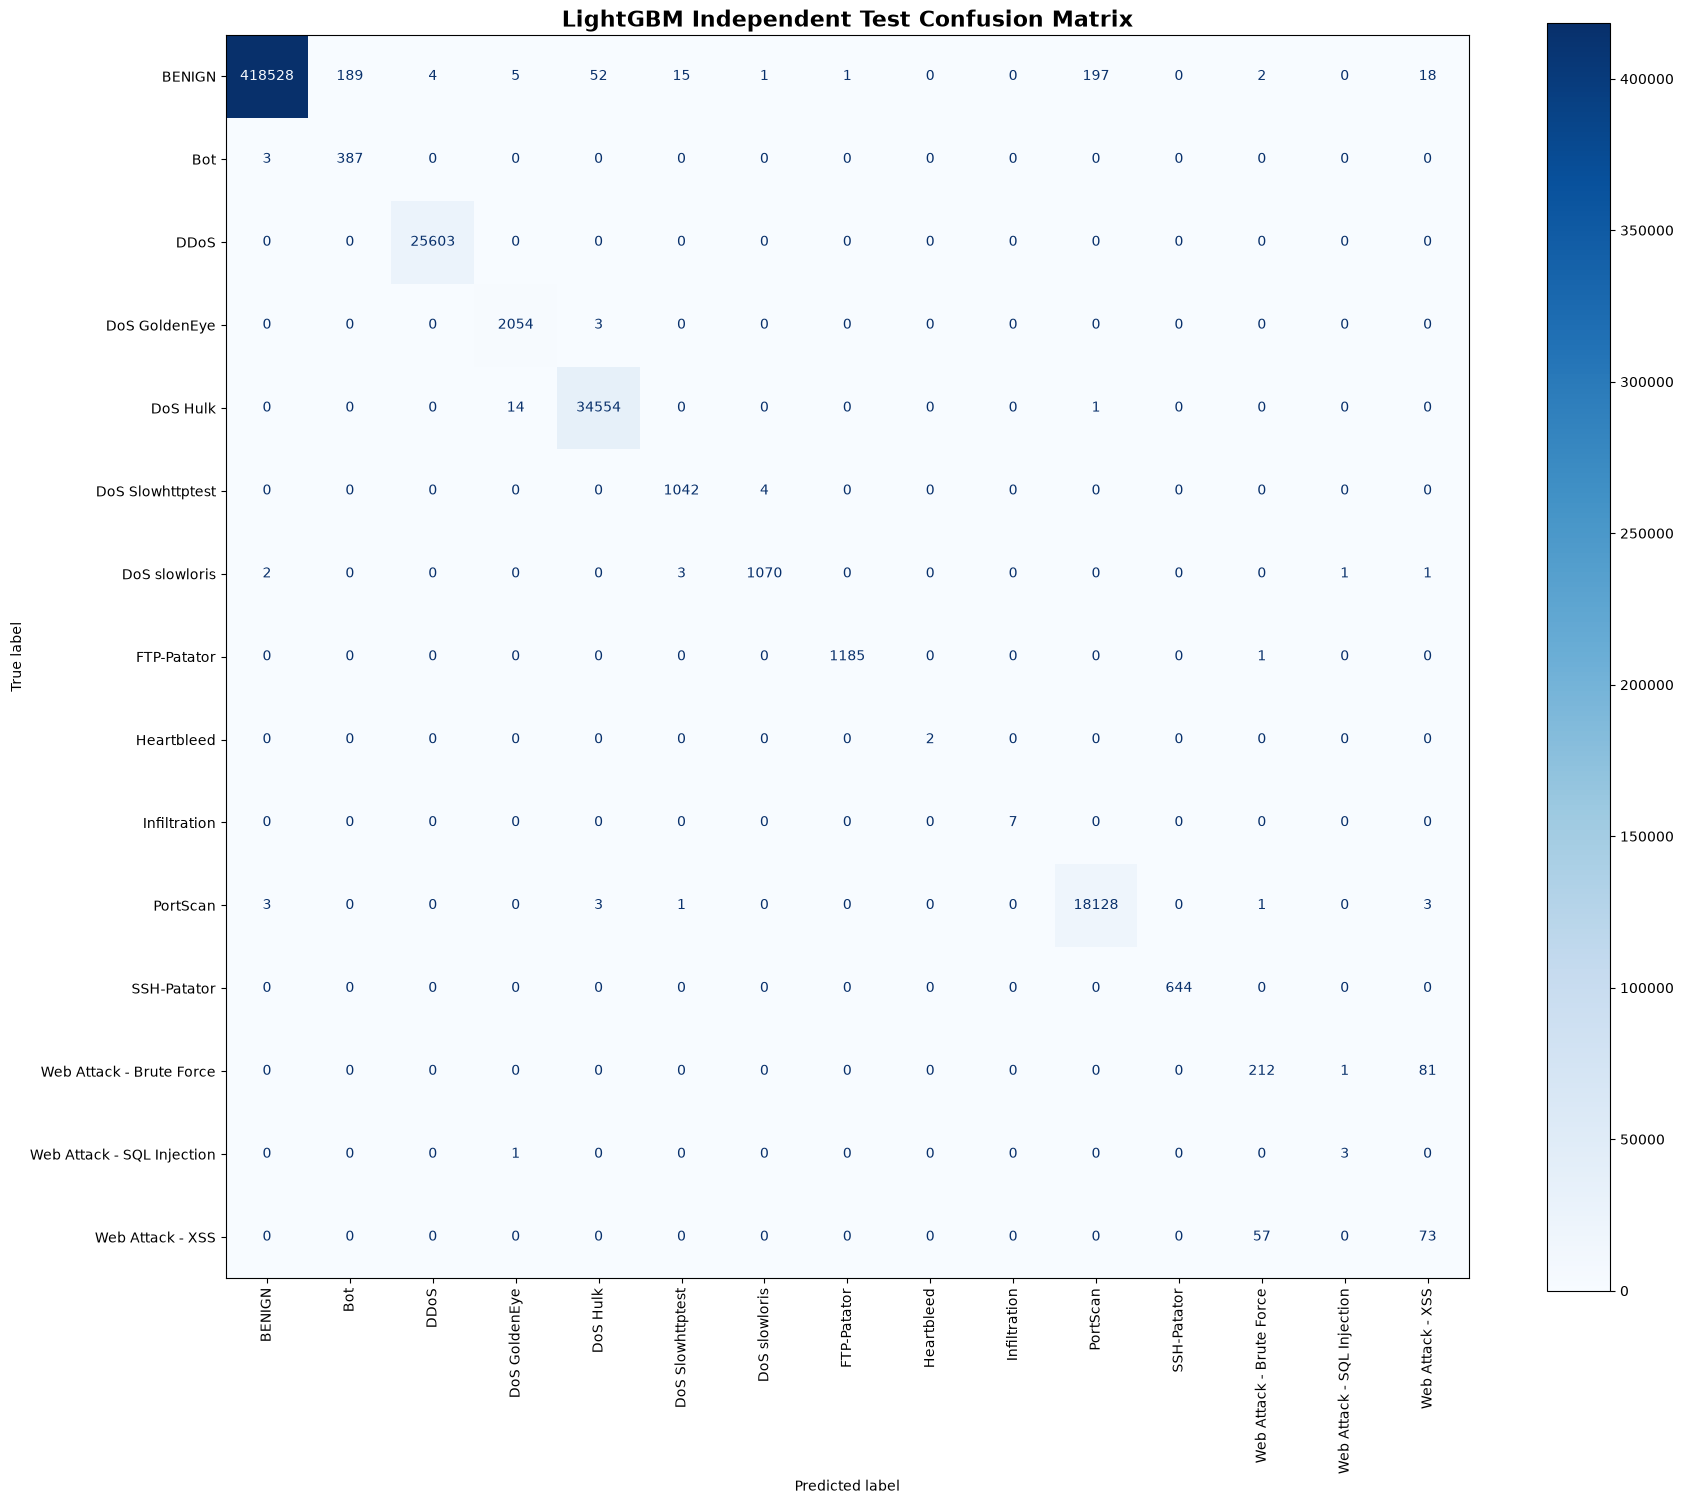

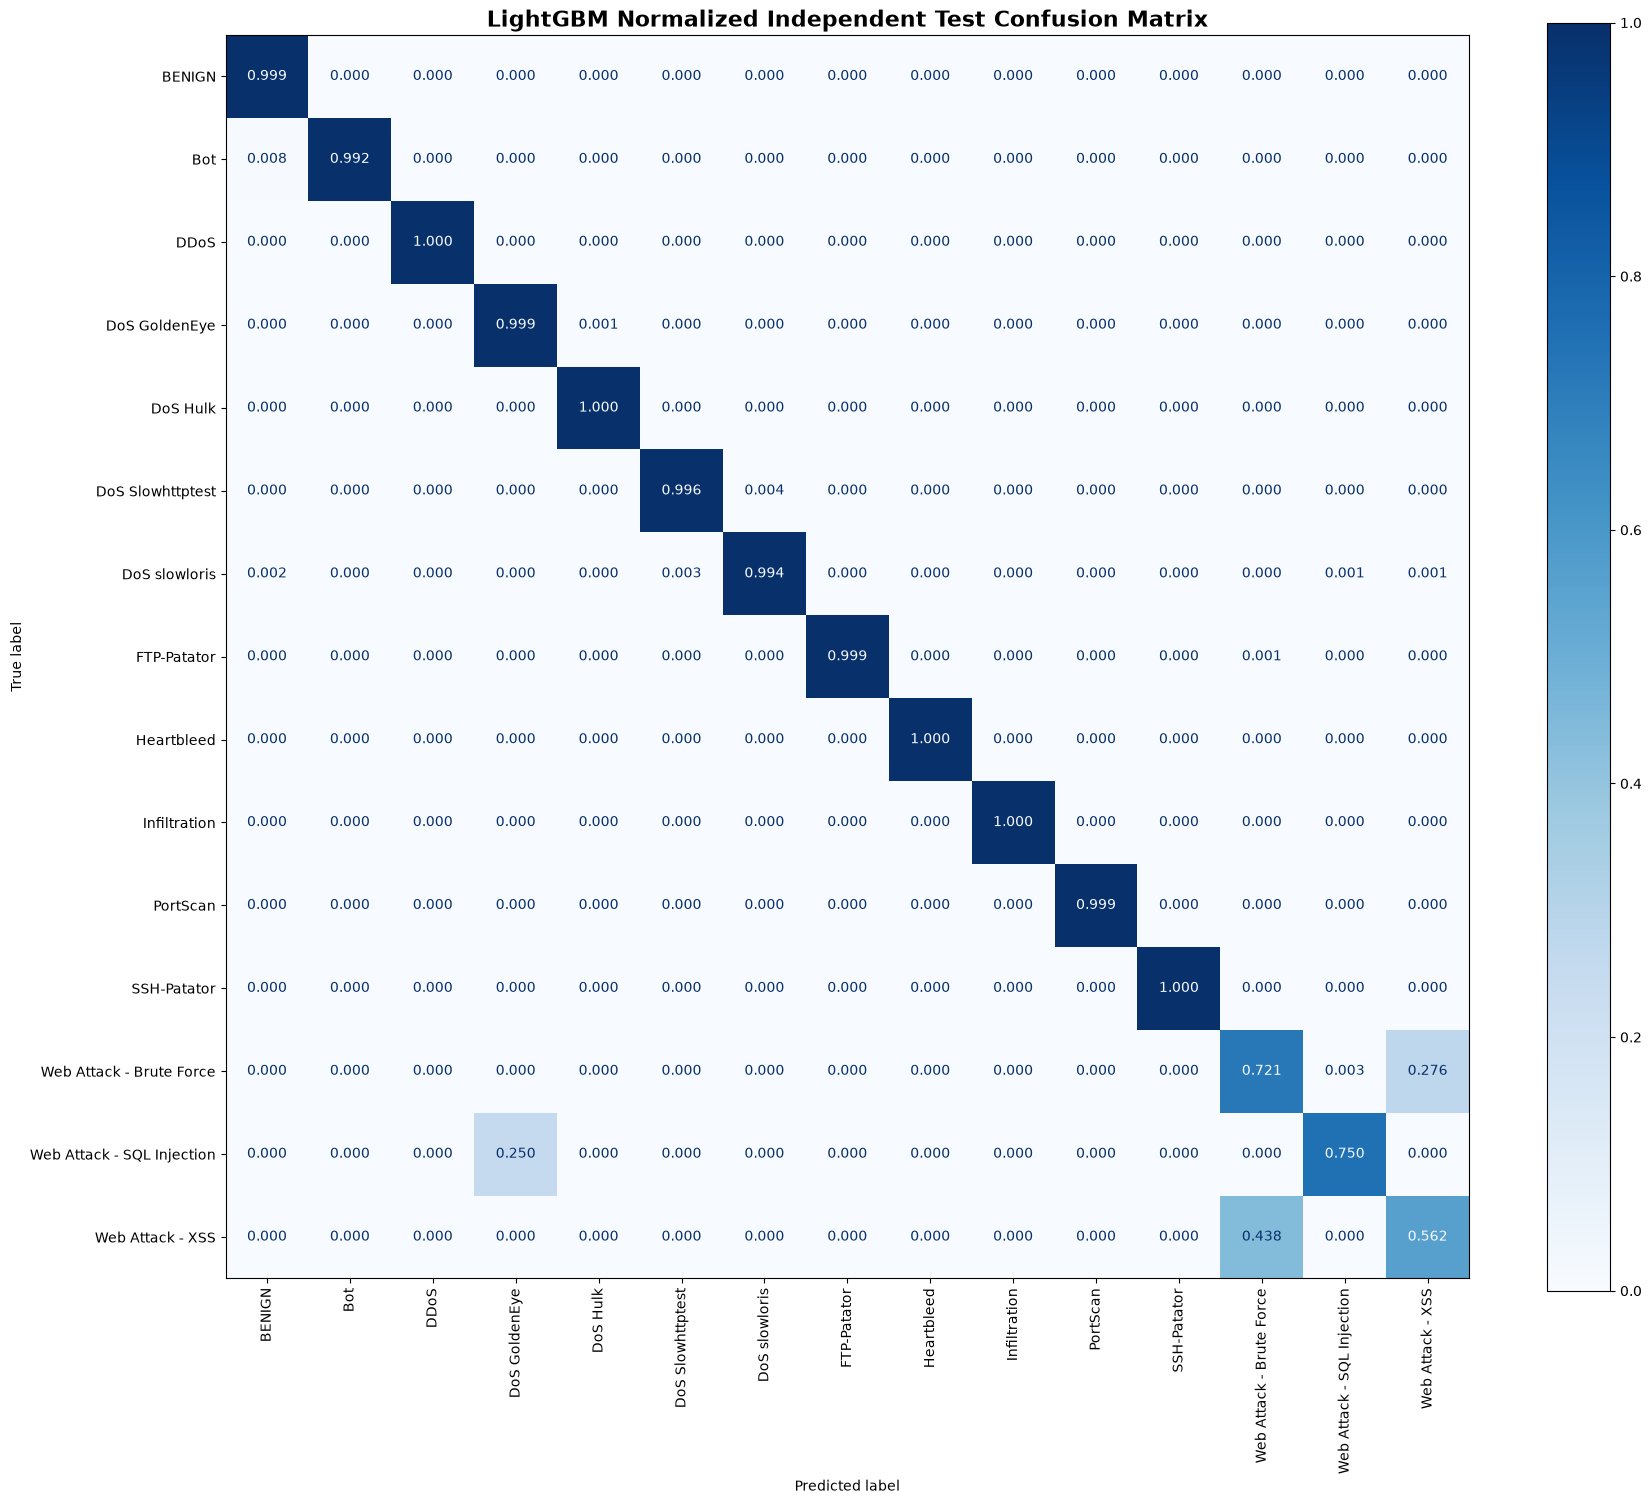


TOP 15 MISCLASSIFICATION PATTERNS
-----------------------------------------------------------------


,Actual_Class,Predicted_Class,Misclassified_Records
0,BENIGN,PortScan,197
1,BENIGN,Bot,189
2,Web Attack - Brute Force,Web Attack - XSS,81
3,Web Attack - XSS,Web Attack - Brute Force,57
4,BENIGN,DoS Hulk,52
5,BENIGN,Web Attack - XSS,18
6,BENIGN,DoS Slowhttptest,15
7,DoS Hulk,DoS GoldenEye,14
8,BENIGN,DoS GoldenEye,5
9,BENIGN,DDoS,4


-----------------------------------------------------------------
Confusion matrix dimensions: (15, 15)
Total evaluated records: 504160
Correct classifications: 503492
Incorrect classifications: 668
Confusion matrix figures saved: 2
Confusion matrix verification: PASS
Independent confusion matrix analysis completed.


In [25]:
# Independent test confusion matrix analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

print("INDEPENDENT TEST CONFUSION MATRIX")
print("-" * 65)

# Generate absolute confusion matrix

independent_cm = confusion_matrix(
    y_independent_test,
    y_independent_pred,
    labels=class_ids
)

# Generate normalized confusion matrix

independent_cm_normalized = confusion_matrix(
    y_independent_test,
    y_independent_pred,
    labels=class_ids,
    normalize="true"
)

# Verify confusion matrix integrity

assert independent_cm.shape == (15, 15)

assert independent_cm.sum() == 504160

assert np.trace(independent_cm) == correct_predictions

assert (
    independent_cm.sum() - np.trace(independent_cm)
    == incorrect_predictions
)

assert np.allclose(
    independent_cm_normalized.sum(axis=1),
    1.0
)

# Create labelled confusion matrix

independent_cm_df = pd.DataFrame(
    independent_cm,
    index=class_names,
    columns=class_names
)

independent_cm_normalized_df = pd.DataFrame(
    independent_cm_normalized,
    index=class_names,
    columns=class_names
)

# Plot absolute confusion matrix

fig, ax = plt.subplots(figsize=(18, 15))

ConfusionMatrixDisplay(
    confusion_matrix=independent_cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=90,
    colorbar=True
)

ax.set_title(
    "LightGBM Independent Test Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "04_independent_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot normalized confusion matrix

fig, ax = plt.subplots(figsize=(18, 15))

ConfusionMatrixDisplay(
    confusion_matrix=independent_cm_normalized,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".3f",
    xticks_rotation=90,
    colorbar=True
)

ax.set_title(
    "LightGBM Normalized Independent Test Confusion Matrix",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "04_independent_confusion_matrix_normalized.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Identify misclassification patterns

misclassification_records = []

for i, actual_class in enumerate(class_names):

    for j, predicted_class in enumerate(class_names):

        if i != j and independent_cm[i, j] > 0:

            misclassification_records.append({
                "Actual_Class": actual_class,
                "Predicted_Class": predicted_class,
                "Misclassified_Records": int(
                    independent_cm[i, j]
                )
            })

independent_misclassification_df = pd.DataFrame(
    misclassification_records
).sort_values(
    "Misclassified_Records",
    ascending=False
).reset_index(drop=True)

assert (
    independent_misclassification_df[
        "Misclassified_Records"
    ].sum() == incorrect_predictions
)

print("\nTOP 15 MISCLASSIFICATION PATTERNS")
print("-" * 65)

display(
    independent_misclassification_df.head(15)
)

print("-" * 65)
print("Confusion matrix dimensions:", independent_cm.shape)
print("Total evaluated records:", independent_cm.sum())
print("Correct classifications:", np.trace(independent_cm))
print("Incorrect classifications:", incorrect_predictions)
print("Confusion matrix figures saved: 2")
print("Confusion matrix verification: PASS")
print("Independent confusion matrix analysis completed.")

In [26]:
# Independent evaluation results persistence

from pathlib import Path
import numpy as np
import pandas as pd
import json

RESULTS_DIR = Path(
    r"C:\Users\pc\XAI-Intrusion-Detection\results"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("INDEPENDENT EVALUATION RESULTS PERSISTENCE")
print("-" * 65)

# Save confusion matrices

independent_cm_df.to_csv(
    RESULTS_DIR / "04_independent_confusion_matrix.csv"
)

independent_cm_normalized_df.to_csv(
    RESULTS_DIR / "04_independent_confusion_matrix_normalized.csv"
)

# Save misclassification patterns

independent_misclassification_df.to_csv(
    RESULTS_DIR / "04_independent_misclassification_patterns.csv",
    index=False
)

# Save classification report

from sklearn.metrics import classification_report

independent_report = classification_report(
    y_independent_test,
    y_independent_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(independent_report).T.to_csv(
    RESULTS_DIR / "04_independent_classification_report.csv"
)

# Save predictions and ground truth

np.save(
    RESULTS_DIR / "04_independent_predictions.npy",
    y_independent_pred
)

np.save(
    RESULTS_DIR / "04_independent_targets.npy",
    y_independent_test
)

# Save evaluation summary

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

evaluation_summary = {
    "model": type(evaluation_model).__name__,
    "test_records": int(len(y_independent_test)),
    "number_of_features": 69,
    "number_of_classes": 15,
    "correct_predictions": int(correct_predictions),
    "incorrect_predictions": int(incorrect_predictions),
    "accuracy": float(
        accuracy_score(y_independent_test, y_independent_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(
            y_independent_test, y_independent_pred
        )
    ),
    "macro_precision": float(
        precision_score(
            y_independent_test, y_independent_pred,
            average="macro", zero_division=0
        )
    ),
    "macro_recall": float(
        recall_score(
            y_independent_test, y_independent_pred,
            average="macro", zero_division=0
        )
    ),
    "macro_f1": float(
        f1_score(
            y_independent_test, y_independent_pred,
            average="macro"
        )
    ),
    "weighted_f1": float(
        f1_score(
            y_independent_test, y_independent_pred,
            average="weighted"
        )
    ),
    "matthews_correlation_coefficient": float(
        matthews_corrcoef(
            y_independent_test, y_independent_pred
        )
    ),
    "cohens_kappa": float(
        cohen_kappa_score(
            y_independent_test, y_independent_pred
        )
    ),
    "prediction_time_seconds": float(prediction_time)
}

with open(
    RESULTS_DIR / "04_independent_evaluation_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(evaluation_summary, f, indent=4)

# Verify saved artifacts

expected_files = [
    "04_independent_confusion_matrix.csv",
    "04_independent_confusion_matrix_normalized.csv",
    "04_independent_misclassification_patterns.csv",
    "04_independent_classification_report.csv",
    "04_independent_predictions.npy",
    "04_independent_targets.npy",
    "04_independent_evaluation_summary.json"
]

for filename in expected_files:

    file_path = RESULTS_DIR / filename

    assert file_path.exists()
    assert file_path.stat().st_size > 0

    print(
        f"{filename}: SAVED | "
        f"{file_path.stat().st_size / 1024:.2f} KB"
    )

# Verify saved predictions

assert np.array_equal(
    np.load(RESULTS_DIR / "04_independent_predictions.npy"),
    y_independent_pred
)

assert np.array_equal(
    np.load(RESULTS_DIR / "04_independent_targets.npy"),
    y_independent_test
)

print("-" * 65)
print("Total evaluation artifacts saved:", len(expected_files))
print("Results persistence verification: PASS")
print("NOTEBOOK 04 COMPLETED SUCCESSFULLY.")

INDEPENDENT EVALUATION RESULTS PERSISTENCE
-----------------------------------------------------------------
04_independent_confusion_matrix.csv: SAVED | 0.88 KB
04_independent_confusion_matrix_normalized.csv: SAVED | 1.92 KB
04_independent_misclassification_patterns.csv: SAVED | 0.89 KB
04_independent_classification_report.csv: SAVED | 1.22 KB
04_independent_predictions.npy: SAVED | 3938.88 KB
04_independent_targets.npy: SAVED | 3938.88 KB
04_independent_evaluation_summary.json: SAVED | 0.58 KB
-----------------------------------------------------------------
Total evaluation artifacts saved: 7
Results persistence verification: PASS
NOTEBOOK 04 COMPLETED SUCCESSFULLY.
